<a href="https://colab.research.google.com/github/wkwkwwk0712-debug/kkyu-repo/blob/main/PMCO_Colab_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PMCO 01 | 사진 특징 → 음악 계획 → (선택) AI 음악 생성
강원대학교 AI융합학과 이원규 / 학번-202313746

## ① 준비 — 라이브러리 설치

In [1]:
!pip -q install -U numpy pillow pandas matplotlib requests beautifulsoup4 google-genai

## ② 매핑 알고리즘 파일 만들기
`%%writefile pmco_core.py`는 아래 Python 코드를 실제 파일로 저장합니다.

In [2]:
%%writefile pmco_core.py
"""PMCO: interpretable prototype image-feature to music-parameter mapping.

These heuristics are design hypotheses, NOT scientifically validated perceptual laws.
"""
from __future__ import annotations
from dataclasses import dataclass, asdict
from io import BytesIO
from typing import Optional
import numpy as np
from PIL import Image

@dataclass
class ImageFeatures:
    brightness: float
    saturation: float
    contrast: float
    complexity: float
    warmth: float

@dataclass
class MusicPlan:
    energy: float
    valence: float
    bpm: int
    genre: str
    instrument: str
    dynamics: str
    explanation: dict

def _clip01(n):
    return float(np.clip(n, 0.0, 1.0))

def extract_features(image: Image.Image | bytes) -> ImageFeatures:
    """Return five [0,1] proxies. 'complexity' is local edge magnitude, not scene motion."""
    if isinstance(image, bytes):
        image = Image.open(BytesIO(image))
    image = image.convert('RGB')
    image.thumbnail((512, 512))
    rgb = np.asarray(image, dtype=np.float32) / 255.0
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    y = 0.2126 * r + 0.7152 * g + 0.0722 * b
    sat = np.asarray(image.convert('HSV'), dtype=np.float32)[..., 1] / 255.0
    diff_h = np.abs(np.diff(y, axis=1)).mean() if y.shape[1] > 1 else 0.0
    diff_v = np.abs(np.diff(y, axis=0)).mean() if y.shape[0] > 1 else 0.0
    # Approximate scaling is a project hypothesis; adjust using labeled data.
    return ImageFeatures(
        brightness=_clip01(y.mean()),
        saturation=_clip01(sat.mean()),
        contrast=_clip01(y.std() / 0.35),
        complexity=_clip01((diff_h + diff_v) / 0.28),
        warmth=_clip01(0.5 + float((r - b).mean()) * 0.9),
    )

def map_music(features: ImageFeatures, energy_override: Optional[float]=None,
              weights: tuple[float,float,float]=(0.40, 0.35, 0.25)) -> MusicPlan:
    """Transparent deterministic mapping: complexity, saturation, contrast -> energy."""
    w = np.asarray(weights, dtype=float)
    if not np.isfinite(w).all() or (w < 0).any() or w.sum() <= 0:
        raise ValueError('weights must be nonnegative and sum to a positive value')
    w /= w.sum()
    contributions = {
        'complexity': float(w[0] * features.complexity),
        'saturation': float(w[1] * features.saturation),
        'contrast': float(w[2] * features.contrast),
    }
    raw = sum(contributions.values())
    energy = _clip01(raw if energy_override is None else energy_override)
    valence = _clip01(0.45 * features.brightness + 0.35 * features.warmth + 0.20 * features.saturation)
    bpm = round(55 + 95 * energy)
    if energy < 0.33:
        genre, dynamics = 'ambient / minimalist', 'soft, slow development'
        instrument = 'warm piano, airy pads' if features.warmth > 0.5 else 'felt piano, soft strings'
    elif energy < 0.67:
        genre, dynamics = 'acoustic / cinematic', 'gentle pulse, moderate intensity'
        instrument = 'acoustic guitar, strings' if features.warmth > 0.5 else 'piano, light percussion'
    else:
        genre, dynamics = 'cinematic / energetic', 'rhythmic, lively accents'
        instrument = 'bright percussion, plucked strings' if features.warmth > 0.5 else 'synths, drums'
    return MusicPlan(energy=energy, valence=valence, bpm=bpm, genre=genre,
                     instrument=instrument, dynamics=dynamics, explanation={
                         'weight_complexity': round(float(w[0]), 3),
                         'weight_saturation': round(float(w[1]), 3),
                         'weight_contrast': round(float(w[2]), 3),
                         'weighted_complexity': round(contributions['complexity'], 4),
                         'weighted_saturation': round(contributions['saturation'], 4),
                         'weighted_contrast': round(contributions['contrast'], 4),
                         'computed_energy_before_override': round(raw, 4),
                         'energy_overridden': energy_override is not None,
                     })

def build_music_prompt(plan: MusicPlan, scene_description: str='') -> str:
    scene = scene_description.strip().replace('\n', ' ')[:500]
    return (
        'Create an original instrumental music clip. No vocals, no lyrics, '
        'no imitation of copyrighted recordings or named artists. '
        f'Target tempo approximately {plan.bpm} BPM. '
        f'Energy {plan.energy:.2f}/1, emotional brightness {plan.valence:.2f}/1. '
        f'Style: {plan.genre}. Instruments: {plan.instrument}. '
        f'Dynamics: {plan.dynamics}. '
        'Express the visual atmosphere with musical texture, not literal sounds. '
        + (f'Image scene notes: {scene}.' if scene else '')
    )

def plan_record(filename: str, features: ImageFeatures, plan: MusicPlan) -> dict:
    base={'filename':filename, **asdict(features)}
    for k,v in asdict(plan).items():
        if k != 'explanation': base[k] = v
    for k,v in plan.explanation.items(): base[k] = v
    return base


Overwriting pmco_core.py


## ③ 사진 업로드
공개 가능한 사진만 사용하세요. 분위기가 다른 사진 두 장을 비교하면 좋습니다.

Saving 활기찬 캠퍼스의 아이들.png to 활기찬 캠퍼스의 아이들.png


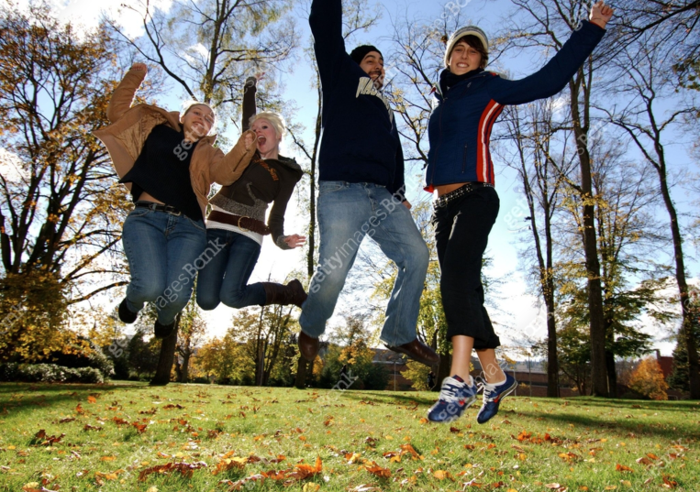

In [27]:
from google.colab import files
from io import BytesIO
from PIL import Image
import matplotlib.pyplot as plt
from pmco_core import extract_features, map_music, build_music_prompt, plan_record
uploaded=files.upload()
if not uploaded: raise ValueError('사진 파일 한 장을 업로드해 줘.')
filename, image_bytes=next(iter(uploaded.items()))
photo=Image.open(BytesIO(image_bytes)).convert('RGB')
display(photo.resize((min(photo.width,700), int(photo.height*min(photo.width,700)/photo.width))))

## ④ 시각 특징 5종 계산
- 밝기/채도/대비/경계 복잡도/붉은색-푸른색 상대 비율(색온감의 간단한 대리지표)
- **움직임** 자체를 인식하지 않는다는 점에 주의!

In [28]:
import pandas as pd
features=extract_features(photo)
display(pd.DataFrame([vars(features)]).T.rename(columns={0:'normalized_value'}))

,normalized_value
brightness,0.465543
saturation,0.399293
contrast,0.808342
complexity,0.442284
warmth,0.552795


## ⑤ 명시적 음악 매핑: E=0.40×복잡도+0.35×채도+0.25×대비, BPM=55+95E
가중치는 **우리가 검증할 초기 가설**입니다. 과학적 고정 법칙이 아닙니다.

In [29]:
music=map_music(features)
print('BPM:',music.bpm,'| Energy:',round(music.energy,3))
print('Genre:',music.genre,'| Instruments:',music.instrument)
print('각 특징의 기여도:',music.explanation)
prompt=build_music_prompt(music)
print('\n음악 생성 프롬프트:\n',prompt)

BPM: 104 | Energy: 0.519
Genre: acoustic / cinematic | Instruments: acoustic guitar, strings
각 특징의 기여도: {'weight_complexity': 0.4, 'weight_saturation': 0.35, 'weight_contrast': 0.25, 'weighted_complexity': 0.1769, 'weighted_saturation': 0.1398, 'weighted_contrast': 0.2021, 'computed_energy_before_override': 0.5188, 'energy_overridden': False}

음악 생성 프롬프트:
 Create an original instrumental music clip. No vocals, no lyrics, no imitation of copyrighted recordings or named artists. Target tempo approximately 104 BPM. Energy 0.52/1, emotional brightness 0.48/1. Style: acoustic / cinematic. Instruments: acoustic guitar, strings. Dynamics: gentle pulse, moderate intensity. Express the visual atmosphere with musical texture, not literal sounds. 


## ⑥ 사용자 개입 실험: 같은 사진으로 에너지만 변경
출력이 바뀌는지 확인하고 나중에 A/B 비교 시 이용합니다.

In [6]:
cases=[map_music(features,energy_override=x) for x in [0.20,0.50,0.85]]
display(pd.DataFrame([{'energy_override':x,'BPM':p.bpm,'genre':p.genre,'instrument':p.instrument} for x,p in zip([0.20,0.50,0.85],cases)]))

,energy_override,BPM,genre,instrument
0,0.20,74,ambient / minimalist,"felt piano, soft strings"
1,0.50,102,acoustic / cinematic,"piano, light percussion"
2,0.85,136,cinematic / energetic,"synths, drums"


## ⑦ Gemini에게 사진 분위기 설명받기

In [7]:
USE_GEMINI = False  # 사용자가 True로 변경해야 실제 유료 API 호출
scene_description = ''
if USE_GEMINI:
    from google.colab import userdata
    from google import genai
    from google.genai import types
    client=genai.Client(api_key=userdata.get('GEMINI_APIKEY'))
    from mimetypes import guess_type
    mime=guess_type(filename)[0] or 'image/jpeg'
    response=client.models.generate_content(
        model='gemini-3.8-flash',
        contents=[types.Part.from_bytes(data=image_bytes,mime_type=mime),
                  '사진에서 관찰 가능한 장면과 고요함/역동성, 계절, 분위기를 한국어로 2문장 설명해줘. 불확실한 내용은 추정이라고 표현해.'],
    )
    scene_description=response.text or ''
    print(scene_description)
else:
    print('Gemini 호출 생략: 비용 없이 수치 알고리즘을 테스트합니다.')
prompt=build_music_prompt(music,scene_description)
print('\n최종 프롬프트:\n',prompt)

Gemini 호출 생략: 비용 없이 수치 알고리즘을 테스트합니다.

최종 프롬프트:
 Create an original instrumental music clip. No vocals, no lyrics, no imitation of copyrighted recordings or named artists. Target tempo approximately 84 BPM. Energy 0.30/1, emotional brightness 0.41/1. Style: ambient / minimalist. Instruments: felt piano, soft strings. Dynamics: soft, slow development. Express the visual atmosphere with musical texture, not literal sounds. 


## ⑧ Lyria 3.5로 실제 MP3 만들기 — 실제 음악 생성
모델 `lyria-3.5-clip-preview` 접근 및 API 상태 잘 확인!!

In [8]:
GENERATE_PAID_MUSIC = False  # 기본 비활성, 의도한 유료 실행만 True
if GENERATE_PAID_MUSIC:
    import base64
    from IPython.display import Audio, display
    from google.colab import userdata
    from google import genai
    client=genai.Client(api_key=userdata.get('GEMINI_APIKEY'))
    interaction=client.interactions.create(model='lyria-3.5-clip-preview',input=prompt)
    audio=interaction.output_audio
    if audio is None or not audio.data:
        raise RuntimeError('생성된 오디오가 없습니다. 모델 사용 권한/응답을 확인하세요.')
    data=base64.b64decode(audio.data) if isinstance(audio.data,str) else audio.data
    mime=(audio.mime_type or 'audio/mpeg')
    ext='.wav' if 'wav' in mime else '.mp3'
    outfile='pmco_generated'+ext
    with open(outfile,'wb') as f: f.write(data)
    display(Audio(filename=outfile))
    print('저장 파일:',outfile,'MIME:',mime)
else:
    print('음원 생성 건너뜀: 프롬프트와 매핑 결과까지만 구현했습니다.')

음원 생성 건너뜀: 프롬프트와 매핑 결과까지만 구현했습니다.


## ⑨ KNIME용 결과 CSV 생성
CSV는 음악 품질의 검증 결과가 아니라 매핑 출력 기록이며, 나중에 사람의 평가 점수를 추가합니다.

In [30]:
from pathlib import Path
from pmco_core import plan_record
import pandas as pd

path = Path("pmco_evaluation.csv")

# 현재 사진의 분석 결과
row = plan_record(filename, features, music)

row.update({
    "prompt": prompt,
    "human_energy_1to5": None,
    "human_calmness_1to5": None,
    "human_music_fit_1to5": None,
    "notes": ""
})

new_data = pd.DataFrame([row])

# 기존 기록이 있다면 합치기
if path.exists():
    old_data = pd.read_csv(path)
    result = pd.concat(
        [old_data, new_data],
        ignore_index=True
    )
    result = result.drop_duplicates(
        subset=["filename"],
        keep="last"
    )
else:
    result = new_data

result.to_csv(
    path,
    index=False,
    encoding="utf-8-sig"
)

print("누적 사진 수:", len(result))
display(result)

누적 사진 수: 6


,filename,brightness,saturation,contrast,complexity,warmth,energy,valence,bpm,genre,...,weighted_complexity,weighted_saturation,weighted_contrast,computed_energy_before_override,energy_overridden,prompt,human_energy_1to5,human_calmness_1to5,human_music_fit_1to5,notes
0,극도의고요함 (1).png,0.431032,0.351406,0.576361,0.091684,0.405016,0.303756,0.406001,84,ambient / minimalist,...,0.0367,0.1230,0.1441,0.3038,False,Create an original instrumental music clip. No...,NaN,NaN,NaN,NaN
1,고요한 숲.jpg,0.196139,0.110485,0.521775,0.214008,0.524013,0.254717,0.293764,79,ambient / minimalist,...,0.0856,0.0387,0.1304,0.2547,False,Create an original instrumental music clip. No...,NaN,NaN,NaN,NaN
2,고요+우울.webp,0.184524,0.609463,0.408404,0.155456,0.391859,0.377596,0.342079,91,acoustic / cinematic,...,0.0622,0.2133,0.1021,0.3776,False,Create an original instrumental music clip. No...,NaN,NaN,NaN,NaN
3,도쿄 시부야 길거리.jpg,0.438638,0.346067,0.584366,0.248000,0.392930,0.366415,0.404126,90,acoustic / cinematic,...,0.0992,0.1211,0.1461,0.3664,False,Create an original instrumental music clip. No...,NaN,NaN,NaN,NaN
4,바다에서 활기차게 노는 네 남성들.png,0.649959,0.288555,0.539637,0.144031,0.542939,0.293516,0.540221,83,ambient / minimalist,...,0.0576,0.1010,0.1349,0.2935,False,Create an original instrumental music clip. No...,NaN,NaN,NaN,NaN
5,활기찬 캠퍼스의 아이들.png,0.465543,0.399293,0.808342,0.442284,0.552795,0.518752,0.482831,104,acoustic / cinematic,...,0.1769,0.1398,0.2021,0.5188,False,Create an original instrumental music clip. No...,None,None,None,


## ⑩ Wikimedia Commons의 이미지 메타데이터 크롤링 및 분석

실제 다운로드와 공개 사용은 각 이미지 라이선스 확인 후 진행, 수업때 배운 크롤링 과정: 'Requests/Beautifulsoup'를 사용

In [ ]:
import requests
from bs4 import BeautifulSoup
params={'action':'query','format':'json','generator':'categorymembers','gcmtitle':'Category:Landscapes',
        'gcmtype':'file','gcmlimit':10,'prop':'imageinfo','iiprop':'url|extmetadata','iiurlwidth':640}
try:
    response=requests.get('https://commons.wikimedia.org/w/api.php',params=params,
        headers={'User-Agent':'PMCO-Classroom/0.1 (educational metadata research)'},timeout=30)
    response.raise_for_status()
    data=response.json()
    records=[]
    for page in data.get('query',{}).get('pages',{}).values():
        info=(page.get('imageinfo') or [{}])[0]
        meta=info.get('extmetadata') or {}
        artist=BeautifulSoup((meta.get('Artist') or {}).get('value',''),'html.parser').get_text(' ',strip=True)
        records.append({'file':page.get('title'),'url':info.get('thumburl'),
                        'page':info.get('descriptionurl'),'artist':artist,
                        'license':(meta.get('LicenseShortName') or {}).get('value','')})
    commons_df=pd.DataFrame(records)
    display(commons_df.head())
    commons_df.to_csv('commons_metadata.csv',index=False,encoding='utf-8-sig')
except Exception as exc:
    print('Commons API 네트워크/권한 오류:',type(exc).__name__,str(exc)[:250])
    print('크롤링은 선택 실습이므로 이미지 매핑과 API 부분은 계속 사용할 수 있습니다.')

,file,url,page,artist,license
0,"File:DRy A, Time For What.jpg",https://thumb.wikimedia.org/wikipedia/commons/...,"https://commons.wikimedia.org/wiki/File:DRy_A,...",Elozzzzzz,CC BY-SA 4.0
1,File:Hadi1361.jpg,https://thumb.wikimedia.org/wikipedia/commons/...,https://commons.wikimedia.org/wiki/File:Hadi13...,Xfatih,CC BY-SA 4.0
2,File:Hill overseeing Roo 2.jpg,https://thumb.wikimedia.org/wikipedia/commons/...,https://commons.wikimedia.org/wiki/File:Hill_o...,Msendama,CC BY-SA 4.0
3,File:Hill overseeing Roo.jpg,https://thumb.wikimedia.org/wikipedia/commons/...,https://commons.wikimedia.org/wiki/File:Hill_o...,Msendama,CC BY-SA 4.0
4,File:Hills at Roo.jpg,https://thumb.wikimedia.org/wikipedia/commons/...,https://commons.wikimedia.org/wiki/File:Hills_...,Msendama,CC BY-SA 4.0


In [ ]:
# ⑩-1 크롤링 이미지 자동 분석 → 기존 CSV에 누적

import time
from io import BytesIO
from pathlib import Path
from urllib.parse import urlparse

import pandas as pd
import requests
from PIL import Image

from pmco_core import (
    extract_features,
    map_music,
    plan_record,
    build_music_prompt
)

MAX_NEW_IMAGES = 30  # 이번에 분석할 새 이미지 수
# None으로 바꾸면 수집된 이미지 중 미분석 이미지 전부 처리

OUTPUT = Path("pmco_evaluation.csv")

# 기존 CSV를 보호하기 위한 사전 검사
if "commons_df" not in globals() or commons_df.empty:
    raise ValueError(
        "먼저 ⑩번 크롤링 셀을 실행하세요."
    )

if not OUTPUT.exists():
    raise FileNotFoundError(
        "기존 pmco_evaluation.csv가 없습니다. "
        "기존 파일을 먼저 Colab에 업로드하세요."
    )

all_results = pd.read_csv(OUTPUT)

if "filename" not in all_results.columns:
    raise ValueError("기존 CSV에 filename 열이 없습니다.")

# 이미 분석한 사진 제외
existing_ids = set(
    all_results["filename"].dropna().astype(str)
)

candidates = commons_df.copy()
candidates["pmco_id"] = (
    "Commons:" + candidates["file"].astype(str)
)

candidates = candidates[
    ~candidates["pmco_id"].isin(existing_ids)
]

# 수집된 이미지 중 일부를 무작위 선정
if MAX_NEW_IMAGES is not None:
    candidates = candidates.sample(
        n=min(MAX_NEW_IMAGES, len(candidates)),
        random_state=42
    )

success = 0
errors = []

session = requests.Session()
session.headers.update({"User-Agent": USER_AGENT})

for _, item in candidates.iterrows():
    try:
        url = str(item["url"])

        # 공식 Commons 이미지 주소만 처리
        if urlparse(url).hostname != "upload.wikimedia.org":
            raise ValueError("공식 Commons 주소가 아닙니다.")

        response = session.get(url, timeout=25)
        response.raise_for_status()

        if len(response.content) > 6_000_000:
            raise ValueError("이미지 크기 제한 초과")

        # ④ 이미지 특징 추출
        with Image.open(BytesIO(response.content)) as photo:
            features = extract_features(photo)

        # ⑤ 음악 매핑
        music = map_music(features)

        # ⑨ 평가 데이터 행 구성
        row = plan_record(
            item["pmco_id"],
            features,
            music
        )

        row.update({
            "prompt": build_music_prompt(music),
            "source": "Wikimedia Commons",
            "source_page": item["page"],
            "source_url": url,
            "artist": item["artist"],
            "license": item["license"],
            "human_energy_1to5": "",
            "human_calmness_1to5": "",
            "human_music_fit_1to5": "",
            "notes": ""
        })

        # 기존 CSV에 한 행씩 추가 후 저장
        all_results = pd.concat(
            [all_results, pd.DataFrame([row])],
            ignore_index=True
        )

        all_results.to_csv(
            OUTPUT,
            index=False,
            encoding="utf-8-sig"
        )

        success += 1
        print(f"완료 {success}: {item['file']}")

    except Exception as exc:
        errors.append(
            (item["file"], str(exc)[:130])
        )
        print(
            f"건너뜀: {item['file']} "
            f"({type(exc).__name__})"
        )

    time.sleep(0.3)

print(f"\n새로 추가된 이미지: {success}장")
print(f"현재 CSV 전체 데이터: {len(all_results)}행")
print(f"분석 실패: {len(errors)}건")

display(all_results.tail(10))

if errors:
    display(
        pd.DataFrame(
            errors,
            columns=["file", "error"]
        ).head(10)
    )


## ⑪ GitHub 저장 (루브릭: 주기적 커밋·브랜치)